In [23]:
# import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import zipfile

print("Library berhasil dimuat.")

Library berhasil dimuat.


In [24]:
# upload dataset dan membaca dataset

uploaded = files.upload()

nama_file = list(uploaded.keys())[0]

df = pd.read_csv(
    nama_file,
    header=None,
    dtype=str,
    encoding="utf-8-sig"
)

print("Nama file:", nama_file)
print("Ukuran data:", df.shape)

display(df.head())

Saving Query Builder Result - Kamis, 22 Oktober 2026 pukul 11.36.18 WIB.csv to Query Builder Result - Kamis, 22 Oktober 2026 pukul 11.36.18 WIB.csv
Nama file: Query Builder Result - Kamis, 22 Oktober 2026 pukul 11.36.18 WIB.csv
Ukuran data: (7, 53)


,0,1,2,3,4,5,6,7,8,9,...,43,44,45,46,47,48,49,50,51,52
0,Kereta Api,Jumlah Penumpang Kereta Api (Ribu Orang),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Januari,Februari,Maret,April,Mei,Juni,Juli,Agustus,September,...,April,Mei,Juni,Juli,Agustus,September,Oktober,November,Desember,Tahunan
3,Jabodetabek,22717,20811,23856,21402,23716,23292,25211,24979,25082,...,30587,28967,30468,32467,30135,-,-,-,-,-
4,Total,29017,26259,29820,28325,30534,30237,32948,31323,31518,...,48280,46964,49541,52123,48321,-,-,-,-,-


In [25]:
# mengolah data 2023 - 2026

baris = df[
    df.iloc[:, 0].fillna("").str.strip() == "Jabodetabek"
].iloc[0]

data = []

for tahun in range(2023, 2027):
    posisi_awal = 1 + (tahun - 2023) * 13

    for bulan in range(1, 13):
        nilai = str(
            baris.iloc[posisi_awal + bulan - 1]
        ).strip()

        if nilai.lower() in ["-", "", "nan"]:
            continue

        data.append({
            "tahun": tahun,
            "bulan": bulan,
            "penumpang": int(nilai)
        })

data_bps = pd.DataFrame(data)

data_bps["tanggal"] = pd.to_datetime(
    dict(
        year=data_bps.tahun,
        month=data_bps.bulan,
        day=1
    )
)

data_bps = data_bps.sort_values(
    "tanggal"
).reset_index(drop=True)

assert len(data_bps) == 44
assert data_bps["tanggal"].is_unique

print("Total data:", len(data_bps))
display(data_bps)

Total data: 44


,tahun,bulan,penumpang,tanggal
0,2023,1,22717,2023-01-01
1,2023,2,20811,2023-02-01
2,2023,3,23856,2023-03-01
3,2023,4,21402,2023-04-01
4,2023,5,23716,2023-05-01
5,2023,6,23292,2023-06-01
6,2023,7,25211,2023-07-01
7,2023,8,24979,2023-08-01
8,2023,9,25082,2023-09-01
9,2023,10,26793,2023-10-01


In [26]:
# Statistik data dan perubahan tahunan
print("RINGKASAN DATA BPS")

ringkasan = data_bps.groupby("tahun")[
    "penumpang"
].agg(["count", "sum", "mean", "min", "max"])

display(ringkasan.round(2))

# Menyusun data per bulan dan tahun
tabel = data_bps.pivot(
    index="bulan",
    columns="tahun",
    values="penumpang"
)

# Menghitung selisih pada bulan yang sama
perubahan_2024 = (
    tabel[2024] - tabel[2023]
).dropna().to_numpy()

perubahan_2025 = (
    tabel[2025] - tabel[2024]
).dropna().to_numpy()

print("\nTabel penumpang bulanan:")
display(tabel)

RINGKASAN DATA BPS


,count,sum,mean,min,max
tahun,,,,,
2023,12,290891,24240.92,20811,26861
2024,12,328154,27346.17,24617,29933
2025,12,348897,29074.75,26974,31777
2026,8,240604,30075.50,27795,32467



Tabel penumpang bulanan:


tahun,2023,2024,2025,2026
bulan,,,,
1,22717.0,26848.0,27522.0,30226.0
2,20811.0,24617.0,27204.0,27795.0
3,23856.0,26012.0,26974.0,29959.0
4,21402.0,25543.0,27552.0,30587.0
5,23716.0,27057.0,28561.0,28967.0
6,23292.0,26739.0,28205.0,30468.0
7,25211.0,29241.0,31401.0,32467.0
8,24979.0,28209.0,28947.0,30135.0
9,25082.0,27608.0,28741.0,NaN


In [27]:
# Fungsi simulasi Monte Carlo
JUMLAH_SIMULASI = 1000
rng = np.random.default_rng(42)

def monte_carlo(tahun, perubahan):
    aktual = tabel[tahun].dropna()

    sebelumnya = tabel[tahun - 1].loc[
        aktual.index
    ].to_numpy()

    # Mengambil sampel historis secara acak
    sampel = rng.choice(
        perubahan,
        size=(len(aktual), JUMLAH_SIMULASI),
        replace=True
    )

    # Menghitung hasil simulasi
    simulasi = np.maximum(
        sebelumnya[:, None] + sampel,
        0
    )

    hasil = pd.DataFrame({
        "bulan": aktual.index,
        "aktual": aktual.to_numpy(),
        "prediksi": simulasi.mean(axis=1),
        "batas_bawah": np.quantile(
            simulasi, 0.10, axis=1
        ),
        "batas_atas": np.quantile(
            simulasi, 0.90, axis=1
        )
    })

    return hasil, simulasi

print("Fungsi Monte Carlo siap digunakan.")

Fungsi Monte Carlo siap digunakan.


In [28]:
# Menjalankan simulasi 2025 dan 2026
# Validasi tahun 2025
hasil_2025, sampel_2025 = monte_carlo(
    2025,
    perubahan_2024
)

# Pengujian tahun 2026
perubahan_historis = np.concatenate([
    perubahan_2024,
    perubahan_2025
])

hasil_2026, sampel_2026 = monte_carlo(
    2026,
    perubahan_historis
)

print("VALIDASI TAHUN 2025")
display(hasil_2025.round(2))

print("\nPENGUJIAN TAHUN 2026")
display(hasil_2026.round(2))

VALIDASI TAHUN 2025


,bulan,aktual,prediksi,batas_bawah,batas_atas
0,1,27522.0,29990.12,28812.0,30979.0
1,2,27204.0,27720.99,26581.0,28748.0
2,3,26974.0,29100.96,27976.0,30143.0
3,4,27552.0,28614.82,27507.0,29674.0
4,5,28561.0,30206.88,29021.0,31198.0
5,6,28205.0,29850.31,28703.0,30870.0
6,7,31401.0,32426.22,31205.0,33382.0
7,8,28947.0,31337.95,30173.0,32340.0
8,9,28741.0,30723.70,29572.0,31739.0
9,10,31777.0,33018.86,31897.0,34064.0



PENGUJIAN TAHUN 2026


,bulan,aktual,prediksi,batas_bawah,batas_atas
0,1,30226.0,29944.40,28484.0,31552.0
1,2,27795.0,29626.63,28166.0,31234.0
2,3,29959.0,29409.09,27936.0,31014.1
3,4,30587.0,29954.59,28514.0,31582.0
4,5,28967.0,31003.75,29523.0,32591.0
5,6,30468.0,30682.42,29167.0,32336.0
6,7,32467.0,33898.10,32363.0,35431.0
7,8,30135.0,31372.44,29909.0,32977.0


In [29]:
# Tabel hasil evaluasi MAE dan WAPE
def evaluasi(hasil, periode):
    aktual = hasil["aktual"].to_numpy()
    prediksi = hasil["prediksi"].to_numpy()

    mae = np.mean(np.abs(aktual - prediksi))

    wape = (
        np.sum(np.abs(aktual - prediksi))
        / np.sum(aktual)
    ) * 100

    cakupan = np.mean(
        (aktual >= hasil["batas_bawah"].to_numpy()) &
        (aktual <= hasil["batas_atas"].to_numpy())
    ) * 100

    return {
        "Periode": periode,
        "MAE (ribu orang)": round(mae, 2),
        "WAPE (%)": round(wape, 2),
        "Cakupan Interval 80% (%)": round(cakupan, 2)
    }

tabel_evaluasi = pd.DataFrame([
    evaluasi(hasil_2025, "Validasi 2025"),
    evaluasi(hasil_2026, "Pengujian 2026")
])

print("TABEL HASIL SIMULASI MONTE CARLO")
display(tabel_evaluasi)

TABEL HASIL SIMULASI MONTE CARLO


,Periode,MAE (ribu orang),WAPE (%),Cakupan Interval 80% (%)
0,Validasi 2025,1390.21,4.78,41.67
1,Pengujian 2026,1026.91,3.41,75.00


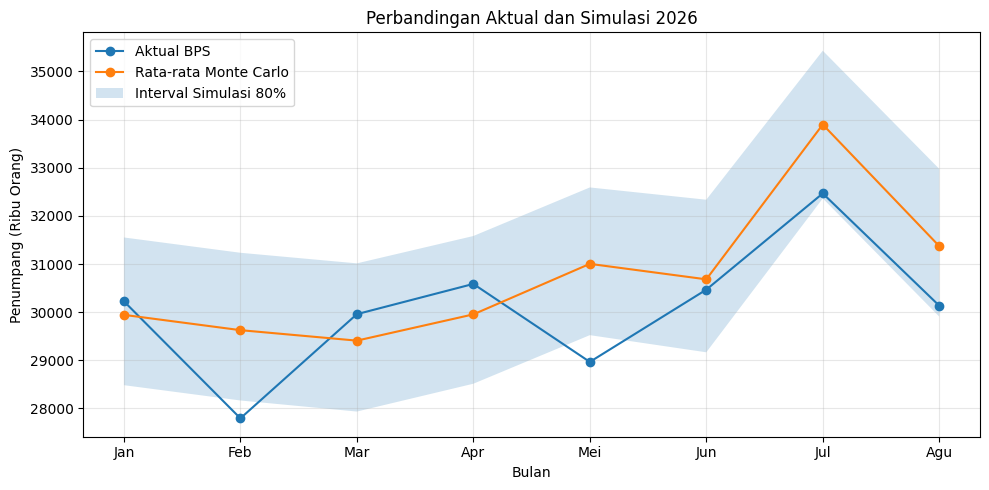

In [30]:
# Grafik perbandingan aktual dan simulasi
plt.figure(figsize=(10, 5))

plt.plot(
    hasil_2026["bulan"],
    hasil_2026["aktual"],
    marker="o",
    label="Aktual BPS"
)

plt.plot(
    hasil_2026["bulan"],
    hasil_2026["prediksi"],
    marker="o",
    label="Rata-rata Monte Carlo"
)

plt.fill_between(
    hasil_2026["bulan"],
    hasil_2026["batas_bawah"],
    hasil_2026["batas_atas"],
    alpha=0.2,
    label="Interval Simulasi 80%"
)

plt.title("Perbandingan Aktual dan Simulasi 2026")
plt.xlabel("Bulan")
plt.ylabel("Penumpang (Ribu Orang)")
plt.xticks(
    range(1, 9),
    ["Jan", "Feb", "Mar", "Apr",
     "Mei", "Jun", "Jul", "Agu"]
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("grafik_perbandingan.png", dpi=300)
plt.show()

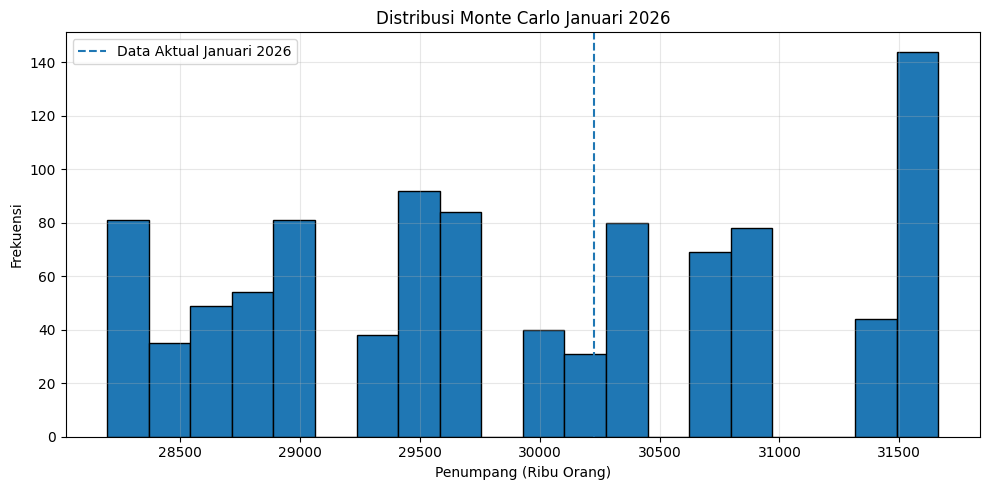

In [31]:
# Grafik distribusi Monte Carlo
plt.figure(figsize=(10, 5))

plt.hist(
    sampel_2026[0],
    bins=20,
    edgecolor="black"
)

plt.axvline(
    hasil_2026.iloc[0]["aktual"],
    linestyle="--",
    label="Data Aktual Januari 2026"
)

plt.title("Distribusi Monte Carlo Januari 2026")
plt.xlabel("Penumpang (Ribu Orang)")
plt.ylabel("Frekuensi")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("grafik_distribusi.png", dpi=300)
plt.show()

In [32]:
# Menyimpan seluruh hasil proyek

# Menyimpan tabel menjadi CSV
data_bps.to_csv("data_bps_bersih.csv", index=False)
hasil_2025.to_csv("validasi_2025.csv", index=False)
hasil_2026.to_csv("pengujian_2026.csv", index=False)
tabel_evaluasi.to_csv("tabel_evaluasi.csv", index=False)

# Membuat ZIP hasil proyek
daftar_file = [
    "data_bps_bersih.csv",
    "validasi_2025.csv",
    "pengujian_2026.csv",
    "tabel_evaluasi.csv",
    "grafik_perbandingan.png",
    "grafik_distribusi.png"
]

with zipfile.ZipFile("hasil_simulasi_kereta.zip", "w") as zipf:
    for nama in daftar_file:
        zipf.write(nama)

print("Semua file berhasil disimpan.")

files.download("hasil_simulasi_kereta.zip")

Semua file berhasil disimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# tabel ringkasan hasil simulasi
import pandas as pd
import numpy as np

def hitung_evaluasi(hasil, periode):
    aktual = hasil["aktual"].to_numpy()
    prediksi = hasil["prediksi"].to_numpy()

    mae = np.mean(np.abs(aktual - prediksi))
    wape = np.sum(np.abs(aktual - prediksi)) / np.sum(aktual) * 100

    cakupan = np.mean(
        (aktual >= hasil["batas_bawah"].to_numpy()) &
        (aktual <= hasil["batas_atas"].to_numpy())
    ) * 100

    return {
        "Periode": periode,
        "MAE (ribu orang)": round(mae, 2),
        "WAPE (%)": round(wape, 2),
        "Cakupan Interval 80% (%)": round(cakupan, 2)
    }

tabel_ringkasan = pd.DataFrame([
    hitung_evaluasi(hasil_2025, "Validasi 2025"),
    hitung_evaluasi(hasil_2026, "Pengujian 2026")
])

display(tabel_ringkasan)

tabel_ringkasan.to_csv(
    "tabel_ringkasan_simulasi.csv", index=False
)

,Periode,MAE (ribu orang),WAPE (%),Cakupan Interval 80% (%)
0,Validasi 2025,1390.21,4.78,41.67
1,Pengujian 2026,1026.91,3.41,75.00


In [34]:
# tabel hasil simulasi setiap bulan
nama_bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli", "Agustus"
]

tabel_bulanan = hasil_2026.copy()

tabel_bulanan["Bulan"] = tabel_bulanan["bulan"].map(
    dict(enumerate(nama_bulan, start=1))
)

tabel_bulanan["Selisih Absolut"] = abs(
    tabel_bulanan["aktual"] - tabel_bulanan["prediksi"]
)

tabel_bulanan = tabel_bulanan.rename(columns={
    "aktual": "Aktual BPS",
    "prediksi": "Monte Carlo",
    "batas_bawah": "Batas Bawah",
    "batas_atas": "Batas Atas"
})

tabel_bulanan = tabel_bulanan[[
    "Bulan", "Aktual BPS", "Monte Carlo",
    "Selisih Absolut", "Batas Bawah", "Batas Atas"
]]

display(tabel_bulanan.round(2))

tabel_bulanan.to_csv(
    "tabel_hasil_bulanan_2026.csv",
    index=False
)

,Bulan,Aktual BPS,Monte Carlo,Selisih Absolut,Batas Bawah,Batas Atas
0,Januari,30226.0,29944.40,281.60,28484.0,31552.0
1,Februari,27795.0,29626.63,1831.63,28166.0,31234.0
2,Maret,29959.0,29409.09,549.91,27936.0,31014.1
3,April,30587.0,29954.59,632.41,28514.0,31582.0
4,Mei,28967.0,31003.75,2036.75,29523.0,32591.0
5,Juni,30468.0,30682.42,214.42,29167.0,32336.0
6,Juli,32467.0,33898.10,1431.10,32363.0,35431.0
7,Agustus,30135.0,31372.44,1237.44,29909.0,32977.0
